# Лабораторна робота №4: Трансформери та моделі Hugging Face

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import transformers
import datasets
import diffusers
import huggingface_hub

transformers.logging.set_verbosity_error()
diffusers.utils.logging.set_verbosity_error()
huggingface_hub.utils.logging.set_verbosity_error()
datasets.disable_progress_bars()

RANDOM_STATE = 24
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Transformers:", transformers.__version__)

Device: cpu
Transformers: 4.57.6


## Частина 1. Машинний переклад EN → UK: трансформер encoder-decoder з нуля

### 1.1. Завантаження датасету

Датасет [ukr-eng](https://www.manythings.org/anki/): пари речень англійською та українською. У кожному рядку англійське речення і його переклад, розділені табуляцією.

In [2]:
import zipfile

zipfile.ZipFile("ukr-eng.zip").extractall(".")
print("ukr.txt:", os.path.getsize("ukr.txt") // 1024, "KB")

ukr.txt: 24473 KB


In [3]:
pairs = []
with open("ukr.txt", encoding="utf-8") as f:
    for line in f:
        parts = line.rstrip("\n").split("\t")
        if len(parts) >= 2:
            pairs.append((parts[0].strip(), parts[1].strip()))

print("Кількість пар:", len(pairs))
for en, uk in random.sample(pairs, 5):
    print(f"{en}  ->  {uk}")

Кількість пар: 160161
I wasn't planning to do that.  ->  Я не планував цим займатися.
I thought that you knew Tom couldn't do that.  ->  Я думала, що ти знаєш, що Том не може цього зробити.
Tom won't understand.  ->  Том не зрозуміє.
He shook hands with me.  ->  Він потис мені руку.
I have read the book.  ->  Я прочитав цю книжку.


### 1.2. Токенізація, словники, train/validation

- Текст переводжу в нижній регістр і розбиваю на слова та розділові знаки
- Беру пари, де речення не довші за 20 слів. Щоб навчання на CPU не тривало надто довго, залишаю 50 000 пар: 90% для навчання, 10% для перевірки
- Для кожної мови свій словник. Додаю службові токени: `[PAD]` для доповнення, `[UNK]` для невідомого слова, `[BOS]` і `[EOS]` для початку й кінця перекладу
- Декодер отримує на вхід `[BOS] + переклад`, а вчиться передбачати `переклад + [EOS]`. Тобто на кожному кроці він вгадує наступне слово

In [4]:
MAX_LEN = 20
MAX_VOCAB = 10000
N_PAIRS = 50000
SPECIALS = ["[PAD]", "[UNK]", "[BOS]", "[EOS]"]
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3


def tokenize(text):
    return re.findall(r"\w+(?:['’]\w+)*|[^\w\s]", text.lower())


pairs = [(en, uk) for en, uk in pairs
         if len(tokenize(en)) <= MAX_LEN and len(tokenize(uk)) <= MAX_LEN - 1]
random.shuffle(pairs)
pairs = pairs[:N_PAIRS]

split = int(0.9 * len(pairs))
train_pairs, val_pairs = pairs[:split], pairs[split:]


def build_vocab(sentences):
    counter = Counter(tok for s in sentences for tok in tokenize(s))
    itos = SPECIALS + [w for w, _ in counter.most_common(MAX_VOCAB - len(SPECIALS))]
    return {w: i for i, w in enumerate(itos)}, itos


en_stoi, en_itos = build_vocab([en for en, _ in train_pairs])
uk_stoi, uk_itos = build_vocab([uk for _, uk in train_pairs])

print("Train:", len(train_pairs), " Val:", len(val_pairs))
print("EN vocab:", len(en_itos), " UK vocab:", len(uk_itos))
print("Приклад токенізації:", tokenize(train_pairs[0][0]), tokenize(train_pairs[0][1]))

Train: 45000  Val: 5000
EN vocab: 7024  UK vocab: 10000
Приклад токенізації: ['she', 'says', 'that', 'she', 'likes', 'flowers', '.'] ['вона', 'каже', ',', 'що', 'любить', 'квіти', '.']


In [5]:
def pad(ids):
    return ids[:MAX_LEN] + [PAD_IDX] * (MAX_LEN - len(ids))


class TranslationDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        en, uk = self.pairs[idx]
        src = [en_stoi.get(t, UNK_IDX) for t in tokenize(en)]
        tgt = [BOS_IDX] + [uk_stoi.get(t, UNK_IDX) for t in tokenize(uk)] + [EOS_IDX]
        return (torch.tensor(pad(src)), torch.tensor(pad(tgt[:-1])), torch.tensor(pad(tgt[1:])))


BATCH_SIZE = 128
train_loader = DataLoader(TranslationDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TranslationDataset(val_pairs), batch_size=BATCH_SIZE)

src, tgt_in, tgt_out = next(iter(train_loader))
print("src:", src.shape, " tgt_in:", tgt_in.shape, " tgt_out:", tgt_out.shape)

src: torch.Size([128, 20])  tgt_in: torch.Size([128, 20])  tgt_out: torch.Size([128, 20])


### 1.3. Архітектура трансформера

Модель навчається з нуля, без готових ваг:
- **Embedding**: кожне слово і його позиція в реченні перетворюються на вектор
- **Encoder** читає англійське речення і будує його представлення
- **Decoder** генерує український переклад слово за словом. Під час генерації він дивиться на вже написані слова (маска не дає бачити майбутні) і на результат енкодера
- **Linear** на виході дає ймовірність кожного слова зі словника

Розміри невеликі (2 шари encoder, 2 шари decoder, вектор розміром 128), щоб модель встигла навчитись на CPU

In [6]:
class TokenPositionalEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model, max_len, dropout):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        pos = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        return self.dropout(self.token_emb(x) + self.pos_emb(pos))


def causal_mask(size, device):
    return torch.triu(torch.ones(size, size, dtype=torch.bool, device=device), diagonal=1)


class Seq2SeqTransformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=128, n_heads=4, num_layers=2, d_ff=256, dropout=0.1):
        super().__init__()
        self.src_emb = TokenPositionalEmbedding(src_vocab, d_model, MAX_LEN, dropout)
        self.tgt_emb = TokenPositionalEmbedding(tgt_vocab, d_model, MAX_LEN, dropout)
        enc_layer = nn.TransformerEncoderLayer(d_model, n_heads, d_ff, dropout, batch_first=True)
        dec_layer = nn.TransformerDecoderLayer(d_model, n_heads, d_ff, dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers, enable_nested_tensor=False)
        self.decoder = nn.TransformerDecoder(dec_layer, num_layers)
        self.output_proj = nn.Linear(d_model, tgt_vocab)

    def encode(self, src):
        return self.encoder(self.src_emb(src), src_key_padding_mask=(src == PAD_IDX))

    def decode(self, tgt_in, memory, src):
        out = self.decoder(
            self.tgt_emb(tgt_in), memory,
            tgt_mask=causal_mask(tgt_in.size(1), tgt_in.device),
            tgt_key_padding_mask=(tgt_in == PAD_IDX),
            memory_key_padding_mask=(src == PAD_IDX),
        )
        return self.output_proj(out)

    def forward(self, src, tgt_in):
        return self.decode(tgt_in, self.encode(src), src)


mt_model = Seq2SeqTransformer(len(en_itos), len(uk_itos)).to(device)
print("Кількість параметрів:", sum(p.numel() for p in mt_model.parameters()))

Кількість параметрів: 4136720


### 1.4. Навчання

Функція втрат `CrossEntropyLoss` рахує, наскільки модель помиляється з наступним словом. Токени `[PAD]` не враховуються. 5 епох

In [7]:
def run_mt_epoch(model, loader, criterion, optimizer=None):
    train_mode = optimizer is not None
    model.train(train_mode)
    total_loss, n_tokens = 0.0, 0
    with torch.set_grad_enabled(train_mode):
        for src, tgt_in, tgt_out in loader:
            src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
            logits = model(src, tgt_in)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            n = (tgt_out != PAD_IDX).sum().item()
            total_loss += loss.item() * n
            n_tokens += n
    return total_loss / n_tokens


EPOCHS_MT = 5
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.AdamW(mt_model.parameters(), lr=5e-4)

for epoch in range(1, EPOCHS_MT + 1):
    start = time.time()
    train_loss = run_mt_epoch(mt_model, train_loader, criterion, optimizer)
    val_loss = run_mt_epoch(mt_model, val_loader, criterion)
    print(f"Епоха {epoch:2d}/{EPOCHS_MT}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  ({time.time() - start:.1f} с)")

Епоха  1/5  train_loss=4.5302  val_loss=3.4642  (147.0 с)
Епоха  2/5  train_loss=3.3614  val_loss=2.8856  (132.4 с)
Епоха  3/5  train_loss=2.8756  val_loss=2.5296  (161.8 с)
Епоха  4/5  train_loss=2.5143  val_loss=2.2416  (164.6 с)
Епоха  5/5  train_loss=2.2206  val_loss=2.0331  (169.5 с)


### 1.5. Приклади перекладу

Переклад будується по одному слову: починаємо з `[BOS]`, щоразу беремо найімовірніше слово, поки модель не видасть `[EOS]`

In [8]:
@torch.no_grad()
def translate(model, sentence):
    model.eval()
    src = torch.tensor([pad([en_stoi.get(t, UNK_IDX) for t in tokenize(sentence)])], device=device)
    memory = model.encode(src)
    ids = [BOS_IDX]
    for _ in range(MAX_LEN - 1):
        logits = model.decode(torch.tensor([ids], device=device), memory, src)
        next_id = logits[0, -1].argmax().item()
        if next_id == EOS_IDX:
            break
        ids.append(next_id)
    return " ".join(uk_itos[i] for i in ids[1:])


print("=== Речення з validation (модель їх не бачила) ===\n")
for en, uk in val_pairs[:8]:
    print("EN:     ", en)
    print("Еталон: ", uk)
    print("Модель: ", translate(mt_model, en), "\n")

print("=== Власні речення ===\n")
for en in ["I love my family.", "Where is the nearest station?", "The weather is nice today.",
           "We study machine learning at the university.", "Can you help me, please?"]:
    print("EN:     ", en)
    print("Модель: ", translate(mt_model, en), "\n")

=== Речення з validation (модель їх не бачила) ===

EN:      Tom is 13, but he still believes in Santa.
Еталон:  Тому тринадцять, але він усе ще вірить у Санту.
Модель:  том — три , але він ще у понеділок . 

EN:      Why don't you put on some clothes?
Еталон:  Чому б вам не одягнутися?
Модель:  чому б тобі не [UNK] на гітарі ? 

EN:      What's your favorite band?
Еталон:  Який твій улюблений гурт?
Модель:  який твій улюблений улюблений [UNK] ? 

EN:      You noticed it, too, didn't you?
Еталон:  Ти теж це помітив, так?
Модель:  ти її її , еге ж ? 

EN:      Apparently you're right.
Еталон:  Ви, очевидно, маєте рацію.
Модель:  [UNK] , ти маєш рацію . 

EN:      They celebrated his success by opening a bottle of wine.
Еталон:  Вони відсвяткували успіх, відкоркувавши пляшку вина.
Модель:  вони [UNK] свою [UNK] [UNK] [UNK] [UNK] . 

EN:      Being sick, I had to stay home.
Еталон:  Я захворів, і мені довелося залишитися вдома.
Модель:  я [UNK] , я був вдома додому . 

EN:      Do you wan

**Висновок.** За 5 епох loss на train знизився з 4.53 до 2.22, на validation з 3.46 до 2.03. Loss ще падає, тож за більшої кількості епох модель стала б кращою.

Короткі фрази модель перекладає правильно: «Do you want to talk?» → «ти хочеш поговорити ?», «Can you help me, please?» → «ти можеш допомогти мені , будь ласка ?».
На довгих реченнях з'являються помилки: невідомі слова `[UNK]` (словник обмежений), повтори («сьогодні сьогодні») та граматичні помилки («свої родина»).
Для кращої якості потрібно більше даних, більша модель і довше навчання

## Частина 2. Текстові моделі Hugging Face

### 2.1. (а) Pipeline з підтримкою української мови

In [9]:
from transformers import pipeline

pipe_device = 0 if torch.cuda.is_available() else -1

#### Zero-shot classification

In [10]:
zero_shot = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli", device=pipe_device)

zero_shot(
    "Збірна України з футболу здобула впевнену перемогу у відбірковому матчі чемпіонату Європи.",
    candidate_labels=["спорт", "політика", "економіка", "наука"],
    hypothesis_template="Цей текст про {}.",
)

{'sequence': 'Збірна України з футболу здобула впевнену перемогу у відбірковому матчі чемпіонату Європи.',
 'labels': ['спорт', 'політика', 'наука', 'економіка'],
 'scores': [0.9955453276634216,
  0.0018883671145886183,
  0.0016278742114081979,
  0.0009384683216921985]}

#### Summarization

In [11]:
summarizer = pipeline("summarization", model="csebuetnlp/mT5_multilingual_XLSum", device=pipe_device)

uk_text = (
    "Київський політехнічний інститут імені Ігоря Сікорського є одним із найбільших технічних університетів України. "
    "Щороку тут навчаються десятки тисяч студентів за інженерними, природничими та гуманітарними спеціальностями. "
    "Університет активно розвиває напрями штучного інтелекту, кібербезпеки та аналізу даних, "
    "співпрацює з міжнародними компаніями та бере участь у європейських освітніх програмах. "
    "Випускники КПІ працюють у провідних IT-компаніях, наукових установах та державних організаціях."
)
summarizer(uk_text, max_length=60, no_repeat_ngram_size=2)

[{'summary_text': 'Київський політехнічний інститут імені Ігоря Сікорського оголосив про відкриття нового навчального закладу.'}]

#### Translation

In [12]:
translator = pipeline("translation", model="Helsinki-NLP/opus-mt-en-uk", device=pipe_device)

translator("Transformers have become the standard architecture for natural language processing.")

[{'translation_text': 'Трансформатори стали стандартною архітектурою для обробки природних мов.'}]

**Результати:**
- **Zero-shot classification**: текст про футбол модель віднесла до класу «спорт» з імовірністю 0.996, хоча прикладів цих класів їй не показували
- **Summarization**: вийшло коротке правильне речення, але модель додала факт, якого немає в тексті («оголосив про відкриття нового навчального закладу»). Модель навчена на новинах, тому пише в стилі новинного заголовка і може вигадувати
- **Translation**: переклад правильний, але «Transformers» перекладено як «Трансформатори» (електротехніка) замість «Трансформери»

### 2.2. (б) Fine-tuning DistilBERT на датасеті з лабораторної №2

#### Дані: 20 Newsgroups, як у лабораторній №2

Повторюю обробку та розбиття з лабораторної №2 (`random_state=42`), тому тестова вибірка та сама: 711 текстів. Модель отримує повний текст без очищення, бо трансформеру потрібні цілі речення

In [13]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

categories = ['sci.space', 'rec.sport.hockey', 'talk.politics.mideast']
news = fetch_20newsgroups(subset='all', categories=categories, remove=('headers', 'footers', 'quotes'))

df_text = pd.DataFrame({'text': news.data, 'label': [news.target_names[i] for i in news.target]})
df_text = df_text[df_text['text'].str.strip() != ''].reset_index(drop=True)


def clean_text(text):
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return ' '.join(w for w in text.split() if len(w) >= 3 and w not in ENGLISH_STOP_WORDS)


df_text['clean_text'] = df_text['text'].apply(clean_text)
df_text = df_text[df_text['clean_text'] != ''].reset_index(drop=True)

train_df, test_df = train_test_split(df_text, test_size=0.25, stratify=df_text['label'], random_state=42)

text_classes = sorted(categories)
label2id = {c: i for i, c in enumerate(text_classes)}
id2label = {i: c for c, i in label2id.items()}

print("Train:", len(train_df), " Test:", len(test_df))
print(test_df['label'].value_counts())

Train: 2133  Test: 711
label
rec.sport.hockey         243
sci.space                239
talk.politics.mideast    229
Name: count, dtype: int64


#### Токенізація та модель

`distilbert-base-uncased`: зменшена версія BERT, вже навчена на англійських текстах. Зверху додається новий шар для 3 класів. Тексти обрізаються до 128 токенів

In [14]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer)

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def to_hf_dataset(df):
    ds = Dataset.from_dict({'text': df['text'].tolist(), 'label': df['label'].map(label2id).tolist()})
    return ds.map(lambda b: tokenizer(b['text'], truncation=True, max_length=128), batched=True)


hf_train = to_hf_dataset(train_df)
hf_test = to_hf_dataset(test_df)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(text_classes), id2label=id2label, label2id=label2id
)

#### Навчання

Повний fine-tuning: навчаються всі ваги моделі, з малим кроком навчання (`2e-5`), 2 епохи

In [15]:
training_args = TrainingArguments(
    output_dir="distilbert-20news",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="no",
    save_strategy="no",
    logging_steps=20,
    report_to="none",
    seed=RANDOM_STATE,
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=hf_train,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
)
trainer.train()

Step,Training Loss
20,0.909600
40,0.485600
60,0.273100
80,0.249800
100,0.181800
120,0.214700
140,0.143200
160,0.142400
180,0.100600
200,0.131600


TrainOutput(global_step=268, training_loss=0.2392718591796818, metrics={'train_runtime': 876.9436, 'train_samples_per_second': 4.865, 'train_steps_per_second': 0.306, 'total_flos': 141279000132096.0, 'train_loss': 0.2392718591796818, 'epoch': 2.0})

#### Оцінка та порівняння з лабораторною №2

In [16]:
pred = trainer.predict(hf_test)
y_true = pred.label_ids
y_pred = pred.predictions.argmax(axis=-1)

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print(classification_report(y_true, y_pred, target_names=text_classes, digits=3))

pd.DataFrame([
    {"model": "TF-IDF + LogisticRegression (лаб. №2)", "accuracy": 0.9536, "f1_macro": 0.953},
    {"model": "DistilBERT fine-tuning", "accuracy": accuracy_score(y_true, y_pred),
     "f1_macro": f1_score(y_true, y_pred, average='macro')},
]).round(4)

Accuracy: 0.9423
                       precision    recall  f1-score   support

     rec.sport.hockey      0.940     0.967     0.953       243
            sci.space      0.948     0.921     0.934       239
talk.politics.mideast      0.939     0.939     0.939       229

             accuracy                          0.942       711
            macro avg      0.942     0.942     0.942       711
         weighted avg      0.942     0.942     0.942       711



,model,accuracy,f1_macro
0,TF-IDF + LogisticRegression (лаб. №2),0.9536,0.9530
1,DistilBERT fine-tuning,0.9423,0.9421


**Висновок.** DistilBERT має accuracy **0.942**, а модель TF-IDF + LogisticRegression з лабораторної №2 мала **0.954**. Тобто трансформер трохи гірший (на 1.1%).

Можливі причини:
- через CPU тексти обрізано до 128 токенів, тож модель бачить лише початок тексту
- лише 2 епохи навчання
- теми легко розрізнити за ключовими словами, тому проста модель тут уже працює дуже добре

Для такої задачі класична модель не гірша і значно швидша

## Частина 3. Робота із зображеннями (Hugging Face)

### 3.1. (а) Text-to-Image (Diffusers)

Генерація зображення за текстом через Stable Diffusion. Модель починає з випадкового шуму і за 20 кроків поступово перетворює його на картинку, яка відповідає запиту. Через CPU розмір 384×384

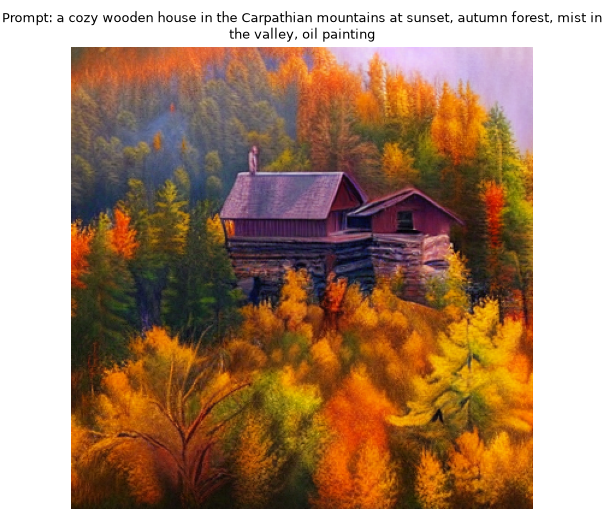

In [17]:
from diffusers import StableDiffusionPipeline

sd_pipe = StableDiffusionPipeline.from_pretrained(
    "CompVis/stable-diffusion-v1-4",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
).to(device)

prompt = "a cozy wooden house in the Carpathian mountains at sunset, autumn forest, mist in the valley, oil painting"
sd_pipe.set_progress_bar_config(disable=True)

generator = torch.Generator(device=device).manual_seed(RANDOM_STATE)
image = sd_pipe(prompt, height=384, width=384, num_inference_steps=20, guidance_scale=7.5, generator=generator).images[0]

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Prompt: " + prompt, fontsize=9, wrap=True)
plt.axis('off')
plt.show()

Зображення відповідає запиту: дерев'яний будинок, осінній ліс, стиль олійного живопису. Гори, захід сонця і туман видно слабко

### 3.2. (б) DINOv2: схожість зображень

#### 10 зображень з Intel Image Classification (лабораторна №3)

У лабораторній №2 не було зображень, тому беру датасет з лабораторної №3: по 2 фото з 5 класів

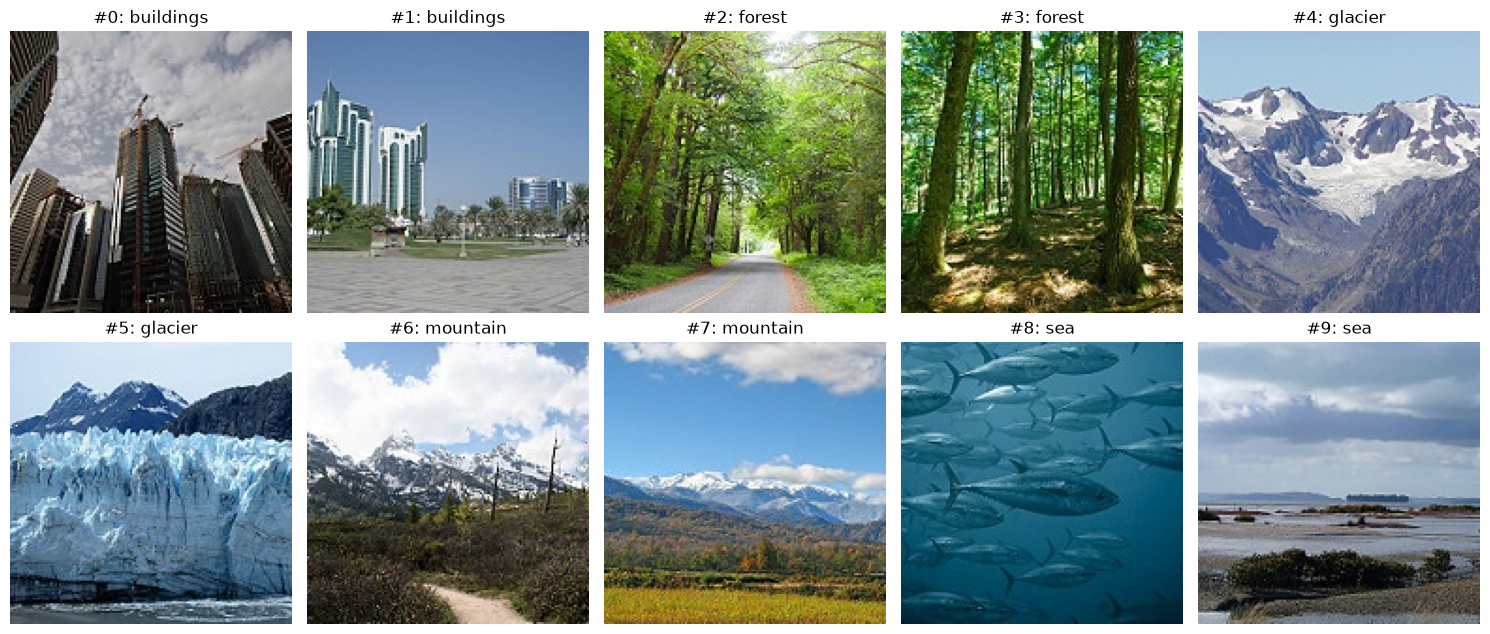

In [18]:
import kagglehub
from PIL import Image

img_path = kagglehub.dataset_download("puneet6060/intel-image-classification")
train_dir = os.path.join(img_path, 'seg_train', 'seg_train')

chosen_classes = ['buildings', 'forest', 'glacier', 'mountain', 'sea']
rng = np.random.default_rng(RANDOM_STATE)
images, names = [], []
for cls in chosen_classes:
    files = sorted(os.listdir(os.path.join(train_dir, cls)))
    for fname in rng.choice(files, size=2, replace=False):
        images.append(Image.open(os.path.join(train_dir, cls, fname)).convert('RGB'))
        names.append(cls)

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(f"#{i}: {names[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

#### Вектори ознак DINOv2 та L2-нормування

DINOv2 перетворює кожне зображення на вектор з 384 чисел. Після L2-нормування довжина кожного вектора дорівнює 1, тому відстань показує лише, наскільки зображення схожі (0 означає однакові)

In [19]:
from transformers import AutoImageProcessor, AutoModel

processor = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
dino = AutoModel.from_pretrained("facebook/dinov2-small").to(device).eval()

with torch.inference_mode():
    inputs = processor(images=images, return_tensors="pt").to(device)
    features = dino(**inputs).last_hidden_state[:, 0, :].cpu()

features_norm = F.normalize(features, p=2, dim=1)
print("Розмір матриці ознак:", tuple(features.shape))
print("Норми до нормування:", features.norm(dim=1).numpy().round(2))
print("Норми після нормування:", features_norm.norm(dim=1).numpy().round(4))

Розмір матриці ознак: (10, 384)
Норми до нормування: [47.58 45.81 47.41 47.65 48.57 49.01 48.39 48.22 49.58 47.32]
Норми після нормування: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


#### Попарні евклідівські відстані

In [20]:
distances = torch.cdist(features_norm, features_norm, p=2).numpy()
labels = [f"#{i} {n}" for i, n in enumerate(names)]
pd.DataFrame(distances, index=labels, columns=labels).round(3)

,#0 buildings,#1 buildings,#2 forest,#3 forest,#4 glacier,#5 glacier,#6 mountain,#7 mountain,#8 sea,#9 sea
#0 buildings,0.000,1.132,1.471,1.417,1.365,1.373,1.413,1.459,1.392,1.441
#1 buildings,1.132,0.000,1.493,1.420,1.408,1.377,1.393,1.414,1.376,1.358
#2 forest,1.471,1.493,0.000,0.963,1.418,1.439,1.284,1.339,1.408,1.368
#3 forest,1.417,1.420,0.963,0.000,1.392,1.413,1.322,1.392,1.373,1.322
#4 glacier,1.365,1.408,1.418,1.392,0.000,1.136,1.017,1.262,1.431,1.396
#5 glacier,1.373,1.377,1.439,1.413,1.136,0.000,1.281,1.353,1.406,1.359
#6 mountain,1.413,1.393,1.284,1.322,1.017,1.281,0.000,1.084,1.435,1.311
#7 mountain,1.459,1.414,1.339,1.392,1.262,1.353,1.084,0.000,1.414,1.240
#8 sea,1.392,1.376,1.408,1.373,1.431,1.406,1.435,1.414,0.000,1.403
#9 sea,1.441,1.358,1.368,1.322,1.396,1.359,1.311,1.240,1.403,0.000


#### Найближча та найвіддаленіша пари

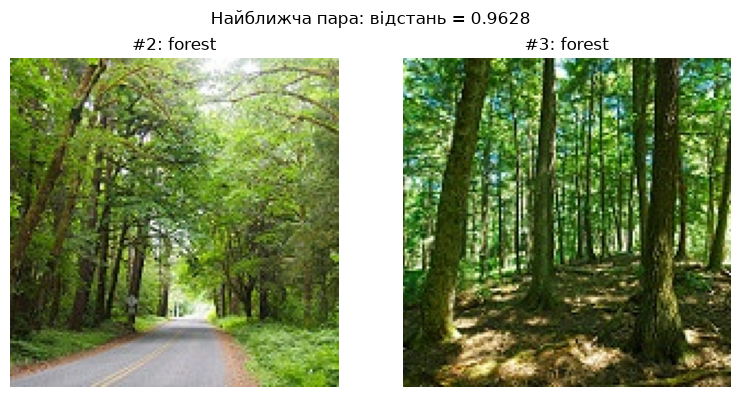

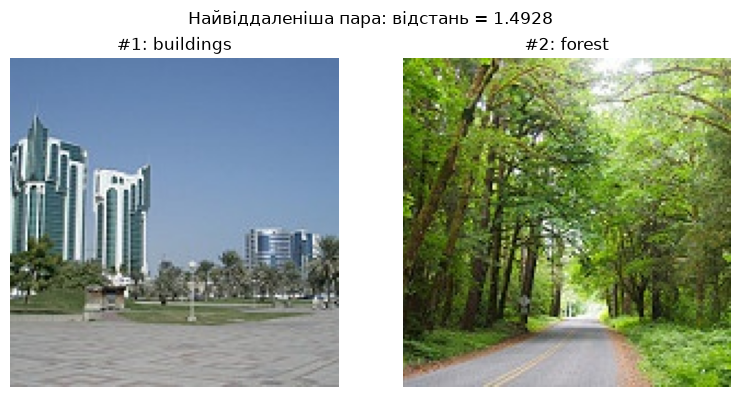

In [21]:
rows, cols = np.triu_indices(len(images), k=1)
pair_dist = distances[rows, cols]
nearest = (rows[pair_dist.argmin()], cols[pair_dist.argmin()])
farthest = (rows[pair_dist.argmax()], cols[pair_dist.argmax()])

for title, (i, j) in [("Найближча пара", nearest), ("Найвіддаленіша пара", farthest)]:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    for ax, idx in zip(axes, (i, j)):
        ax.imshow(images[idx])
        ax.set_title(f"#{idx}: {names[idx]}")
        ax.axis('off')
    fig.suptitle(f"{title}: відстань = {distances[i, j]:.4f}")
    plt.tight_layout()
    plt.show()

**Висновок.**
- **Найближча пара: #2 і #3 (обидва ліс), відстань 0.963.** Це збігається з тим, що бачить людина: на обох фото зелений ліс з високими деревами
- **Найвіддаленіша пара: #1 (будівлі) і #2 (ліс), відстань 1.493.** Теж логічно: місто з хмарочосами і лісова дорога зовсім різні

Ще з таблиці відстаней видно, що льодовик #4 ближчий до гори #6, ніж до іншого льодовика #5, бо на #4 і #6 засніжені вершини. А два фото моря (#8 під водою з рибами, #9 берег) далекі одне від одного.
Тобто DINOv2 порівнює те, що зображено на фото, а не назву класу, і загалом результати збігаються з візуальним сприйняттям